In [ ]:
'''
figure out more versions of SNR: whole image and chunked
(including for stars we don't have good matches for)

second half: new signal calculation with area
'''

In [1]:
import pandas as pd
import numpy as np
import review_findings_functions as rff
import importlib
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/3155/inference_star_info_r12_bands")

In [12]:
df['star_ra'].isnull().values.any()

True

In [15]:
np.sum(df['star_ra'].isnull())

156

In [88]:
def add_snr_whole_and_chunks_test(df, half_aperture=2, tracking=True):
    """
    returns the dataframe with new columns for snr, stdv, and average value
    for both whole time series and chunks of it
    """
    snr_whole = np.zeros(len(df))
    snr_chunks = np.zeros(len(df))
    stdv_whole = np.zeros(len(df))
    stdv_chunks = np.zeros(len(df))
    avg_whole = np.zeros(len(df))
    avg_chunks = np.zeros(len(df))
    for index in tqdm(df.index[:100]):
        # print(index)
        tot, maxcols =rff. get_tot(df, index, half_aperture, tracking)
        ratio, stdv, avg = rff.get_snr_whole_image(tot, df, index)
        ratio_ch, stdv_ch, avg_ch = rff.get_snr_chunks(tot, df, index)
        snr_whole[index] = ratio
        snr_chunks[index] = ratio_ch
        stdv_whole[index] = stdv
        stdv_chunks[index] = stdv_ch
        avg_whole[index] = avg
        avg_chunks[index] = avg_ch
    df["snr_whole"] = snr_whole
    df["snr_chunks"] = snr_chunks
    df["stdv_whole"] = stdv_whole
    df["stdv_chunks"] = stdv_chunks
    df["avg_whole"] = avg_whole
    df["avg_chunks"] = avg_chunks
    return df

In [89]:
df_plus_snr = add_snr_whole_and_chunks_tes(df)

  0%|          | 0/100 [00:00<?, ?it/s]

In [94]:
df_plus_snr.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', '0', '1', '2', '3', '4', 'filename',
       'type', 'row_from_nn', 'col_from_nn', 'detection_size', 'quadrant',
       'sobel_ratio', 'snr_center', 'snr_max', 'snr_min', 'closest_x',
       'closest_y', 'Diff', 'star_ra', 'star_dec', 'Band', 'gaia_source_id',
       'g_mag', 'bp_rp', 'rp_mag_ztf_ri', 'bp_mag_ztf_g', 'variability',
       'in_vari_summary', 'snr_whole', 'snr_chunks', 'stdv_whole',
       'stdv_chunks', 'avg_whole', 'avg_chunks'],
      dtype='object')

In [131]:
df_plus_snr = pd.read_csv("/home/3155/df_plus_snr")

/tmp/ipykernel_48701/2276682459.py:1: DtypeWarning: Columns (26,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df_plus_snr = pd.read_csv("/home/3155/df_plus_snr")


Text(0.5, 0, 'SNR')

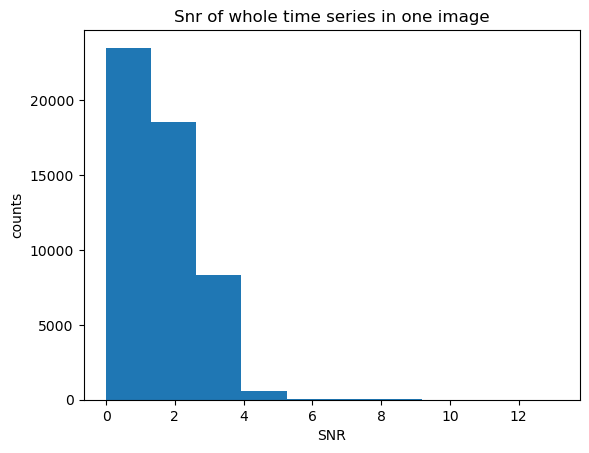

In [133]:
plt.hist(np.abs(df_plus_snr['snr_whole']))
plt.title("Snr of whole time series in one image")
plt.ylabel('counts')
plt.xlabel('SNR')

(0.0, 14.0)

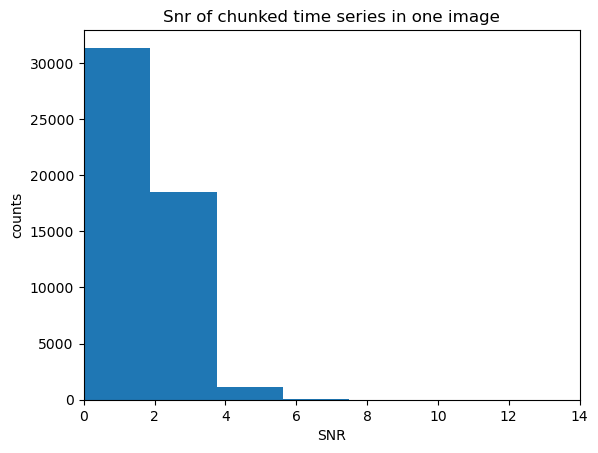

In [138]:
plt.hist(np.abs(df_plus_snr['snr_chunks']),bins=40)
plt.title("Snr of chunked time series in one image")
plt.ylabel('counts')
plt.xlabel('SNR')
plt.xlim(0,14)

In [ ]:
#also want to make number of candidates per star
#one with snr limit and one not, probably
#but easy enough to swap df going into it

In [111]:
name, counts = np.unique(df['gaia_source_id'], return_counts=True)

In [112]:
len(name)

897

Text(0, 0.5, 'Number of sources (stars)')

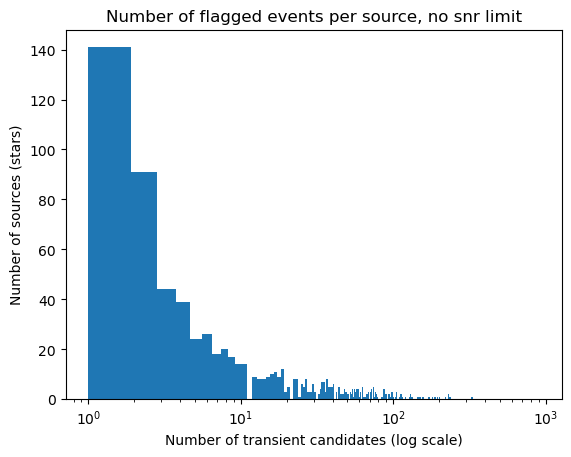

In [125]:
plt.hist(counts,bins=1000)
plt.title("Number of flagged events per source, no snr limit")
# plt.xlim(0,500)
plt.xscale("log")
plt.xlabel("Number of transient candidates (log scale)")
plt.ylabel("Number of sources (stars)")

Text(0, 0.5, 'Number of sources (stars)')

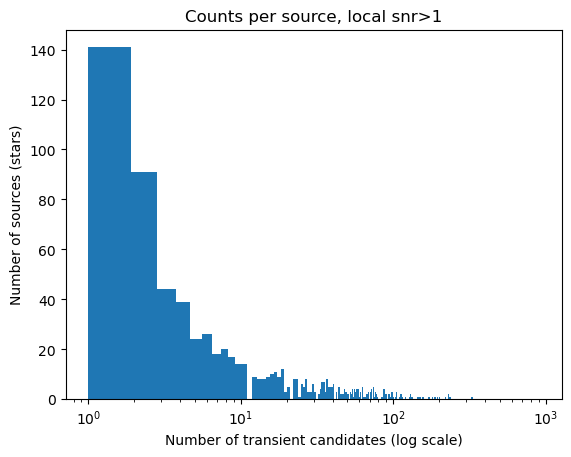

In [130]:
df_snr_limited = df[np.abs(df['snr_center'])>1]
name, counts = np.unique(df_snr_limited['gaia_source_id'], return_counts=True)
plt.hist(counts,bins=1000)
plt.title("Counts per source, local snr>1")
# plt.xlim(0,500)
plt.xscale("log")
plt.xlabel("Number of transient candidates (log scale)")
plt.ylabel("Number of sources (stars)")

Text(0, 0.5, 'Number of sources (stars)')

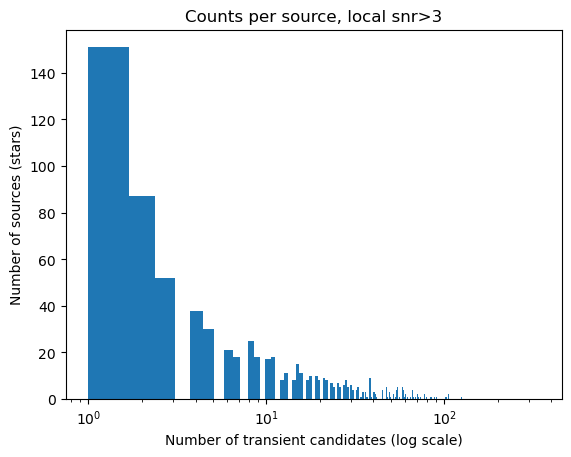

In [152]:
df_snr_limited = df[np.abs(df['snr_center'])>3]
name, counts = np.unique(df_snr_limited['gaia_source_id'], return_counts=True)
plt.hist(counts,bins=500)
plt.title("Counts per source, local snr>3")
# plt.xlim(0,500)
plt.xscale("log")
plt.xlabel("Number of transient candidates (log scale)")
plt.ylabel("Number of sources (stars)")

In [ ]:
#i want one where the snr is big for chunks but not whole

In [161]:
df_chunks_large = df_plus_snr[np.abs(df_plus_snr['snr_chunks'])>3]

In [170]:
df_chunks_large[np.abs(df_chunks_large['snr_whole'])<2.5]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary,snr_whole,snr_chunks,stdv_whole,stdv_chunks,avg_whole,avg_chunks
2031,2031,2031,2031,24418,72,72,327,327,ztf_20221020157697_000640_zi_c04_x_0026.,neg,...,3.928472,8.092337,VARIABLE,True,-2.479538,-3.206870,1375.369326,1085.911937,33667.425648,33739.522880
2836,2836,2836,2836,34252,173,173,441,441,ztf_20221020148032_000686_zg_c16_x_0014.,neg,...,8.247607,8.18237,NOT_AVAILABLE,False,-2.363700,-3.107300,86.945358,62.241851,1852.810341,1840.701723
6186,6186,6186,6186,73550,113,113,485,485,ztf_20221020154120_000640_zi_c04_x_0022.,neg,...,3.928472,8.092337,VARIABLE,True,-2.320779,-3.119967,1146.618848,894.654219,33772.515327,33902.758523
11185,11185,11185,11185,134063,19,19,73,73,ztf_20221020138241_000686_zi_c14_x_0000.,neg,...,9.374539,11.02686,NOT_AVAILABLE,False,-2.264047,-3.262144,163.963393,114.598968,1108.731286,1111.348822
11966,11966,11966,11966,143432,8,8,105,105,ztf_20221020148032_000686_zg_c16_x_0010.,pos,...,6.780638,8.060617,NOT_AVAILABLE,False,2.406057,3.107390,70.324218,55.938735,1576.309829,1571.690437
13030,13030,13030,13030,157019,87,87,181,181,ztf_20221020157697_000640_zi_c16_x_0004.,neg,...,7.578772,8.20702,NOT_AVAILABLE,False,-1.754817,-3.792168,87.940883,43.095024,1584.550654,1593.654024
18091,18091,18091,18091,218223,127,127,239,239,ztf_20221020148032_000686_zg_c03_x_0019.,neg,...,7.340594,7.349636,NOT_AVAILABLE,False,-2.485817,-3.060244,158.428113,132.951353,4294.692430,4307.732694
18465,18465,18465,18465,223259,115,115,205,205,ztf_20221020157697_000640_zi_c16_x_0005.,neg,...,7.578772,8.20702,NOT_AVAILABLE,False,-2.001140,-3.272111,64.816578,41.518824,1595.105949,1601.253130
22159,22159,22159,22159,267764,123,123,222,222,ztf_20221020157697_000640_zi_c16_x_0019.,neg,...,7.578772,8.20702,NOT_AVAILABLE,False,2.298710,3.681734,64.866817,38.205552,1601.441783,1609.889093
24520,24520,24520,24520,298185,163,163,910,910,ztf_20221020148032_000686_zg_c14_x_0023.,neg,...,5.292495,5.08798,NOT_AVAILABLE,False,-2.413446,-3.065356,1055.620625,893.931892,30702.491799,30895.028429


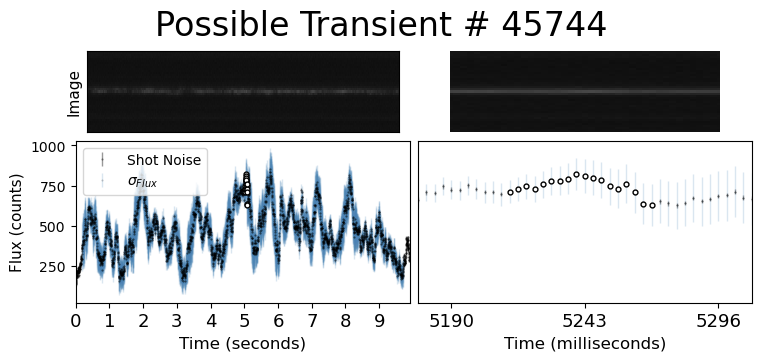

In [173]:
rff.plot_time_series_again_aperture(df_chunks_large, 45744)#, tracking=True, half_aperture=1)

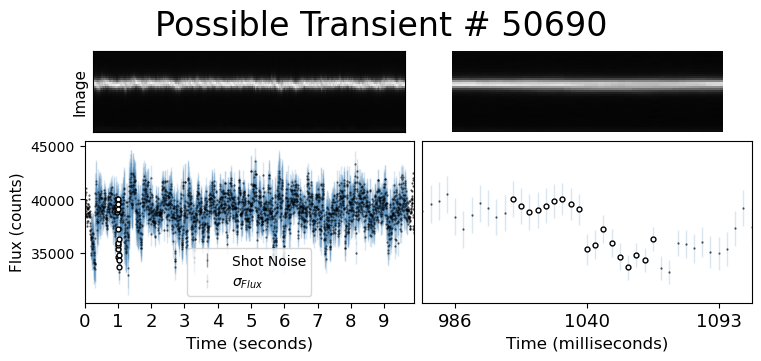

In [171]:
rff.plot_time_series_again_aperture(df_chunks_large, 50690)#, tracking=True, half_aperture=1)

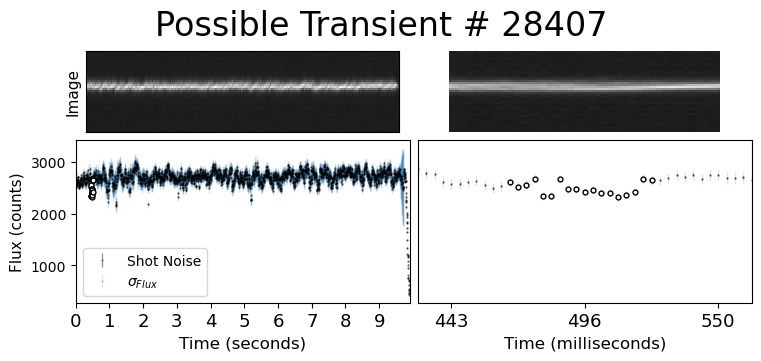

In [169]:
rff.plot_time_series_again_aperture(df_chunks_large, 28407)#, tracking=True, half_aperture=1)

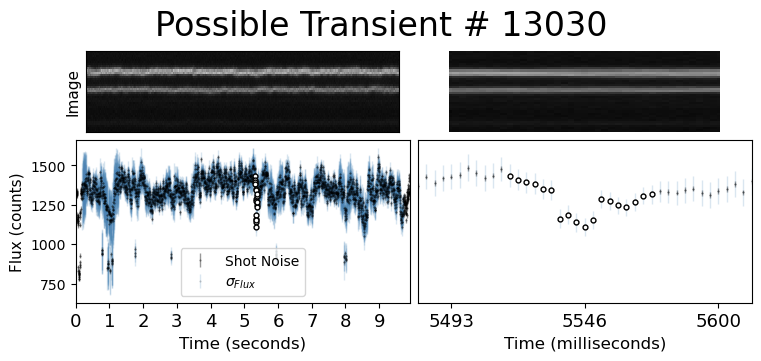

In [168]:
rff.plot_time_series_again_aperture(df_chunks_large, 13030, tracking=True, half_aperture=1)

Text(0, 0.5, 'counts')

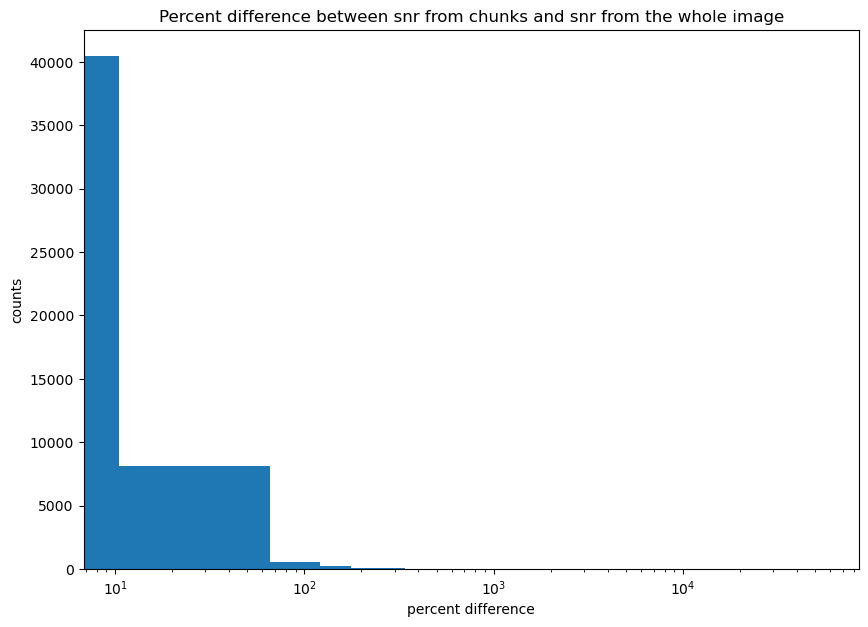

In [205]:
plt.hist(100*(np.abs(df_plus_snr['snr_chunks'])-np.abs(df_plus_snr['snr_whole']))/np.abs(df_plus_snr['snr_whole']),
          bins=1000)
# plt.xlim(-3,3)
plt.xscale("log")
plt.title("Percent difference between snr from chunks and snr from the whole image")
plt.xlabel("percent difference")
plt.ylabel("counts")

Text(0, 0.5, 'counts')

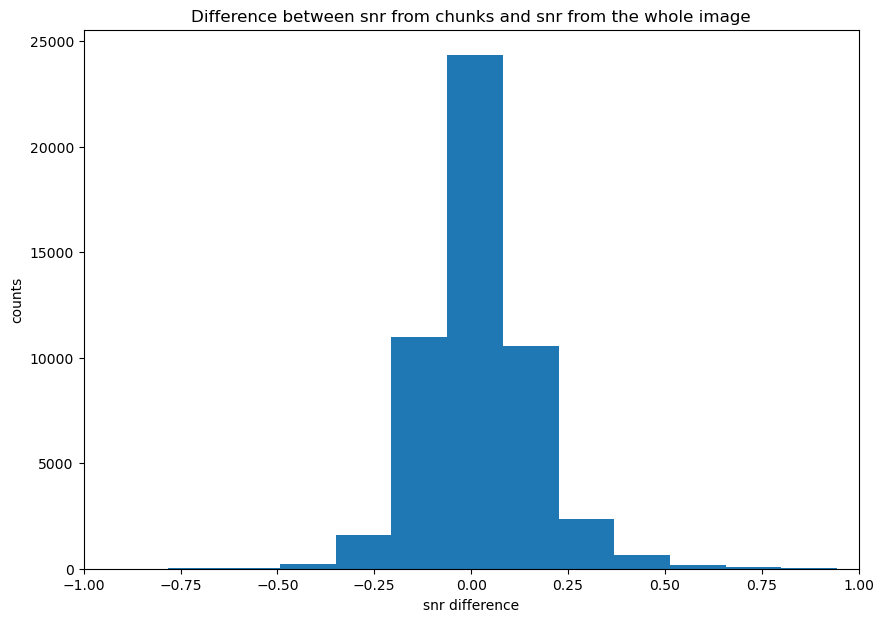

In [206]:
plt.hist(np.abs(df_plus_snr['snr_chunks'])-np.abs(df_plus_snr['snr_whole']),bins=500)
plt.xlim(-1,1)
plt.title("Difference between snr from chunks and snr from the whole image")
plt.xlabel("snr difference")
plt.ylabel("counts")

In [174]:
df_whole_large = df_plus_snr[np.abs(df_plus_snr['snr_whole'])>3]

In [180]:
df_whole_large[np.abs(df_whole_large['snr_chunks'])<2.7]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary,snr_whole,snr_chunks,stdv_whole,stdv_chunks,avg_whole,avg_chunks
1148,1148,1148,1148,13678,80,80,749,749,ztf_20221020297847_000449_zr_c12_x_0016.,neg,...,5.914348,6.45162,NOT_AVAILABLE,False,-3.027036,-2.694465,275.435168,291.718292,10596.729793,10549.002241
1440,1440,1440,1440,17241,3,3,39,39,ztf_20221020141806_000686_zi_c13_x_0021.,pos,...,4.998009,4.841869,NOT_AVAILABLE,False,3.004989,2.681308,263.431247,291.181509,8420.142956,8431.003803
2424,2424,2424,2424,29207,88,88,782,782,ztf_20221020148032_000686_zg_c14_x_0000.,neg,...,5.292495,5.08798,NOT_AVAILABLE,False,-3.125821,-2.679333,862.088186,959.555572,30908.135878,30784.370992
5390,5390,5390,5390,64014,25,25,95,95,ztf_20221020163819_000640_zg_c11_x_0020.,neg,...,7.569540,7.518358,VARIABLE,True,-3.007767,-2.581484,94.751366,103.636782,3773.429984,3755.976642
8376,8376,8376,8376,99333,170,170,540,540,ztf_20221020163819_000640_zg_c02_x_0009.,neg,...,5.542603,6.6894717,NOT_AVAILABLE,False,-3.197285,-2.641184,196.088122,229.823856,6167.374393,6147.431797
8377,8377,8377,8377,99334,171,171,541,541,ztf_20221020163819_000640_zg_c02_x_0009.,neg,...,5.542603,6.6894717,NOT_AVAILABLE,False,-3.197285,-2.641184,196.088122,229.823856,6167.374393,6147.431797
10266,10266,10266,10266,122685,159,159,586,586,ztf_20221020148032_000686_zg_c13_x_0004.,neg,...,6.694501,6.9650025,VARIABLE,True,-3.022406,-2.675991,197.970917,217.135331,7629.696699,7612.400344
13533,13533,13533,13533,163617,51,51,396,396,ztf_20221020163819_000640_zg_c10_x_0011.,neg,...,5.409686,5.5348315,NOT_AVAILABLE,False,-3.434923,-2.697432,654.510401,771.584463,22450.177089,22283.280842
26577,26577,26577,26577,322825,40,40,130,130,ztf_20221020163819_000640_zg_c15_x_0001.,neg,...,5.927102,6.9949417,NOT_AVAILABLE,False,-3.141302,-2.678306,141.564312,160.436645,4864.175774,4849.177897
27667,27667,27667,27667,335870,73,73,297,297,ztf_20221020297847_000449_zr_c12_x_0016.,neg,...,5.121076,5.5948224,NOT_AVAILABLE,False,-3.017372,-2.625292,546.529136,600.306519,22794.690875,22721.589177


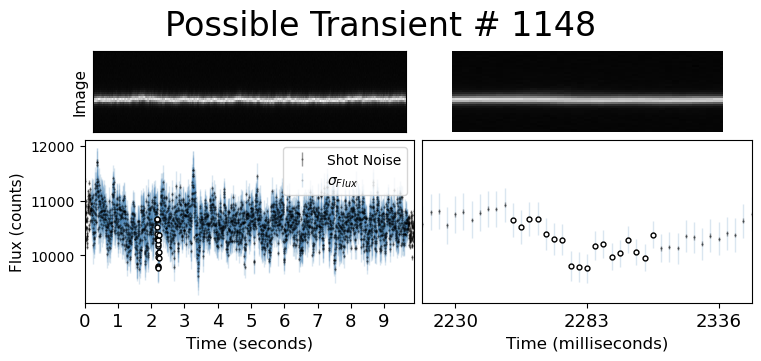

In [181]:
rff.plot_time_series_again_aperture(df_whole_large, 1148)#, tracking=True, half_aperture=1)

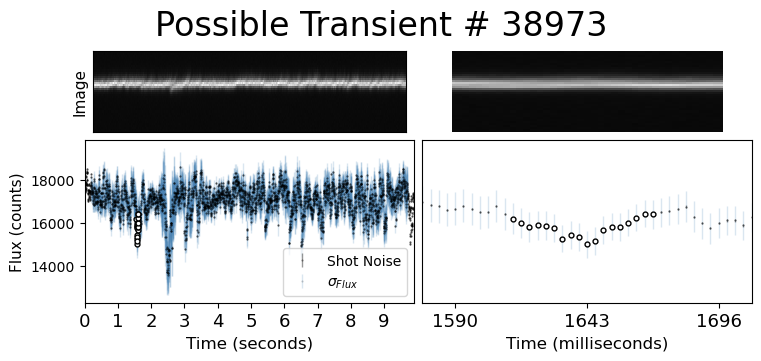

In [212]:
rff.plot_time_series_again_aperture(df_whole_large, 38973)#, tracking=True, half_aperture=1)

In [226]:
def drop_garbage(df):
    return df.drop(['Unnamed: 0.2',
                  'Unnamed: 0.1',
                  'Unnamed: 0',
                  '0','1','2','3','4'],1)

In [ ]:
#let's try a little filtering action
df_candidates_pos = df_plus_snr[df_plus_snr['snr_center']>3]

df_candidates_pos = drop_garbage(df_candidates_pos)

df_candidates_pos_best = df_candidates_pos.sort_values(['snr_center'])[-100:]

df_candidates_pos_best = count_candidates(df_candidates_pos_best, df_plus_snr, local_snr_limit=1)

df_few = df_candidates_pos_best[df_candidates_pos_best['num_cand_in_star']<10]

In [266]:
def count_candidates(short_df, original_df, local_snr_limit=1):
    counts = np.zeros(len(short_df))
    snr_filtered = original_df[np.abs(original_df['snr_center'])>local_snr_limit]
    for i, row in enumerate(short_df.iterrows()):
        count = np.sum(snr_filtered['gaia_source_id']==df_candidates_pos_best.iloc[i]['gaia_source_id'])
        counts[i] = count
    short_df['num_cand_in_star'] = counts
    return short_df

In [290]:
df_candidates_pos_best = count_candidates(df_candidates_pos_best, df_plus_snr, local_snr_limit=1)

Text(0, 0.5, 'Number of stars')

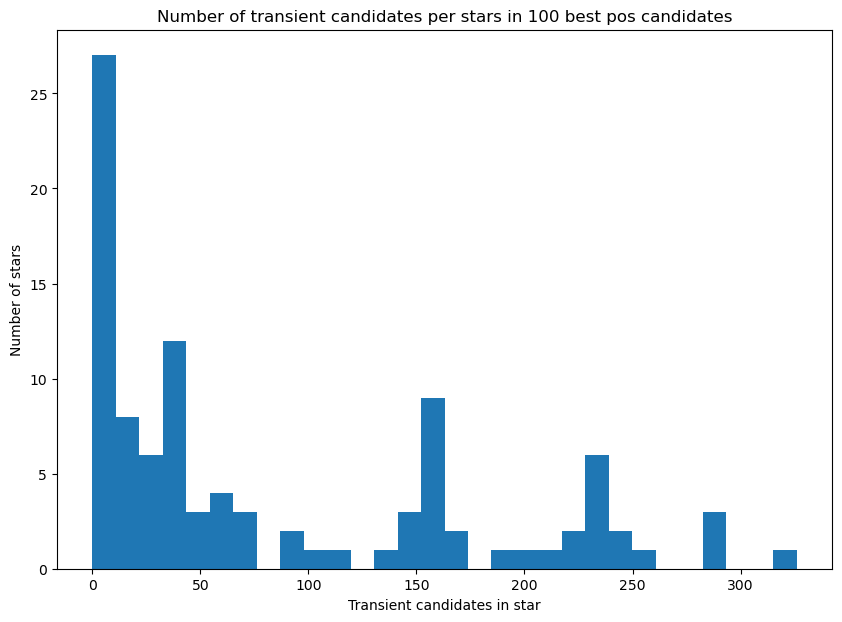

In [292]:
plt.hist(df_candidates_pos_best['num_cand_in_star'],bins=30)
plt.title("Number of transient candidates per stars in 100 best pos candidates")
plt.xlabel("Transient candidates in star")
plt.ylabel("Number of stars")

In [299]:
df_few = df_candidates_pos_best[df_candidates_pos_best['num_cand_in_star']<10]

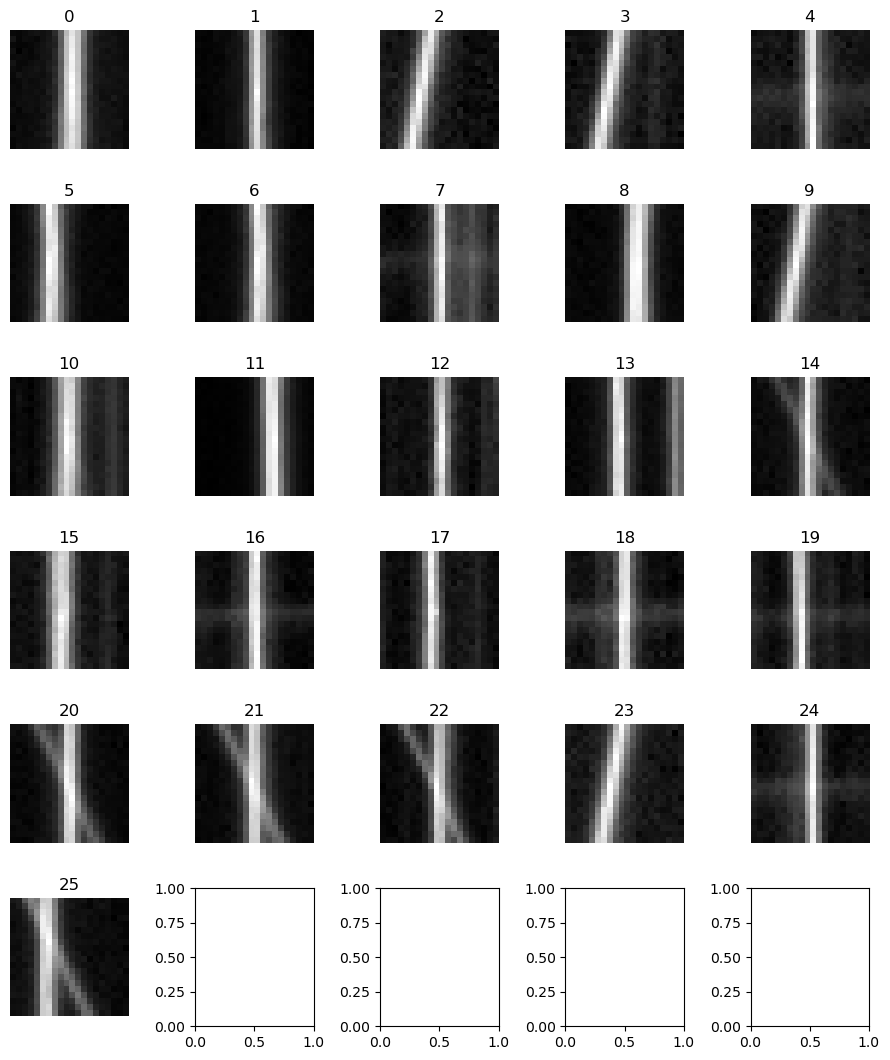

In [301]:
rff.inspect_df_with_quadrant(df_few,'1020')

In [302]:
df_few

,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min,...,bp_mag_ztf_g,variability,in_vari_summary,snr_whole,snr_chunks,stdv_whole,stdv_chunks,avg_whole,avg_chunks,num_cand_in_star
46567,ztf_20221020148032_000686_zg_c02_x_0013.,pos,3034.400000,2391.200000,10.0,3,14.643307,5.090686,5.090686,-1.419453,...,8.461642,NOT_AVAILABLE,False,3.588392,3.163875,48.337475,55.069200,1758.643132,1757.864874,1.0
9594,ztf_20221020154120_000640_zi_c10_x_0029.,pos,1527.400000,3021.720000,25.0,1,11.932924,5.162325,5.162325,-1.157874,...,8.9826565,NOT_AVAILABLE,False,4.294945,4.405094,65.629317,64.593422,2426.012911,2423.347107,9.0
2823,ztf_20221020148032_000686_zg_c16_x_0014.,pos,2909.000000,514.000000,5.0,4,5.697741,5.201119,5.322337,4.851509,...,11.133613,NOT_AVAILABLE,False,5.140252,3.200024,133.239648,202.179408,12.271319,50.177824,3.0
2802,ztf_20221020148032_000686_zg_c16_x_0014.,pos,1400.500000,776.333333,6.0,4,5.886429,5.248575,5.248575,4.764318,...,9.977549,NOT_AVAILABLE,False,5.169960,3.094655,130.890588,205.276135,32.480952,73.921206,1.0
19322,ztf_20221020138241_000686_zi_c02_x_0029.,pos,2689.821429,532.678571,28.0,2,9.861324,5.251425,5.251425,-1.339967,...,10.7273855,NOT_AVAILABLE,False,5.364638,5.360883,23.747675,24.224445,716.860206,714.393467,1.0
45629,ztf_20221020294271_000449_zr_c14_x_0021.,pos,1779.727273,1770.545455,11.0,3,12.035884,5.305365,5.661872,-0.583163,...,NaN,NaN,NaN,3.912160,4.021280,86.876492,84.115396,2762.607458,2764.230639,0.0
45628,ztf_20221020294271_000449_zr_c14_x_0021.,pos,1779.960000,1766.080000,25.0,3,12.035884,5.305365,5.661872,-0.583163,...,NaN,NaN,NaN,3.912160,4.021280,86.876492,84.115396,2762.607458,2764.230639,0.0
19324,ztf_20221020138241_000686_zi_c02_x_0029.,pos,2698.428571,295.285714,14.0,2,11.887737,5.306154,8.248251,-0.847414,...,9.143597,NOT_AVAILABLE,False,4.094529,4.039815,31.792292,32.331337,931.186860,930.748709,3.0
46275,ztf_20221020163819_000640_zg_c03_x_0020.,pos,3001.571429,1839.142857,14.0,1,14.293284,5.328289,5.328289,0.621443,...,20.704556,NOT_AVAILABLE,False,3.945666,4.078792,71.132870,65.096525,2350.550236,2365.701618,7.0
2820,ztf_20221020148032_000686_zg_c16_x_0014.,pos,2825.000000,528.600000,5.0,4,6.572043,5.487287,5.566598,4.966547,...,11.133613,NOT_AVAILABLE,False,5.069603,9.553441,131.565667,71.679782,40.305037,22.502223,3.0


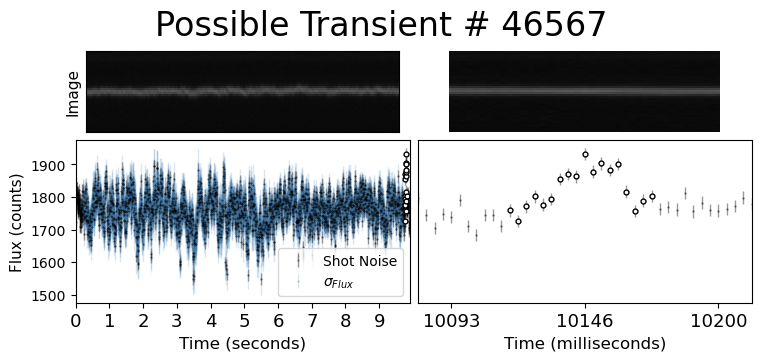

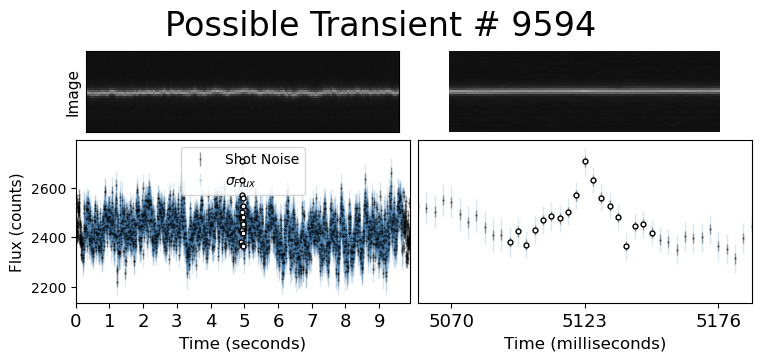

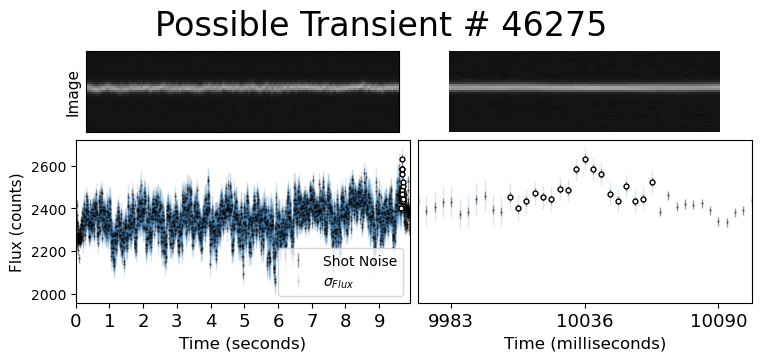

In [306]:
to_check = [46567, 9594,46275]
for index in to_check:
    rff.plot_time_series_again_aperture(df_candidates_pos_best, index)#, tracking=True, half_aperture=1)

In [258]:
'''
starting NEGATIVE here
'''

NameError: name 'snr_filtered' is not defined

In [309]:
#let's try a little filtering action
df_candidates_pos = df_plus_snr[df_plus_snr['snr_center']<-3]

df_candidates_pos = drop_garbage(df_candidates_pos)

df_candidates_pos_best = df_candidates_pos.sort_values(['snr_center'])[:100]

df_candidates_pos_best = count_candidates(df_candidates_pos_best, df_plus_snr, local_snr_limit=1)

df_few = df_candidates_pos_best[df_candidates_pos_best['num_cand_in_star']<10]

/tmp/ipykernel_48701/1301796427.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  return df.drop(['Unnamed: 0.2',


In [310]:
df_few

,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min,...,bp_mag_ztf_g,variability,in_vari_summary,snr_whole,snr_chunks,stdv_whole,stdv_chunks,avg_whole,avg_chunks,num_cand_in_star
49429,ztf_20221020138241_000686_zi_c03_x_0026.,neg,1142.500000,2353.500000,12.0,1,8.844425,-8.364856,1.326753,-8.898036,...,8.491894,NOT_AVAILABLE,False,-2.558029,-2.870420,209.653513,185.030456,2946.571596,2941.386874,2.0
45083,ztf_20221020297847_000449_zr_c06_x_0026.,neg,2617.750000,2788.541667,24.0,2,23.964281,-6.856683,-1.849368,-6.856683,...,NaN,NaN,NaN,-5.250511,-5.154831,543.855187,547.796339,27071.566512,27039.846651,0.0
42258,ztf_20221020294271_000449_zr_c14_x_0029.,neg,2098.928571,1319.785714,14.0,4,15.902457,-6.794768,1.669109,-6.794768,...,NaN,NaN,NaN,-3.623414,-4.293796,167.408249,149.440532,4231.992011,4267.069775,0.0
17426,ztf_20221020138241_000686_zi_c08_x_0000.,pos,18.473684,2976.078947,38.0,1,11.059417,-6.709987,-2.568073,-10.698993,...,12.50627,NOT_AVAILABLE,False,-5.687944,-14.764012,89.786211,34.983181,1244.415747,1250.208912,1.0
42252,ztf_20221020294271_000449_zr_c14_x_0029.,neg,546.818182,1326.272727,11.0,4,12.468706,-6.367428,-1.431364,-6.940353,...,NaN,NaN,NaN,-5.010677,-5.723827,164.262000,149.464583,4233.712208,4266.157898,0.0
35976,ztf_20221020297847_000449_zr_c16_x_0026.,neg,1405.666667,251.888889,9.0,1,10.941658,-6.229236,2.226097,-6.229236,...,NaN,NaN,NaN,-3.919674,-4.837964,48.934809,39.298945,1378.869787,1377.188165,0.0
9399,ztf_20221020148032_000686_zg_c11_x_0026.,neg,919.586957,1102.760870,46.0,1,7.123142,-6.175447,0.680107,-6.175447,...,8.655097,NOT_AVAILABLE,False,-6.235933,-6.261033,44.563156,44.864318,1263.623796,1266.627955,3.0
46008,ztf_20221020141806_000686_zi_c16_x_0007.,neg,1727.000000,102.142857,7.0,2,12.664315,-6.170753,-0.264863,-6.725109,...,8.517778,NOT_AVAILABLE,False,-6.351132,-7.147888,47.075583,43.215613,1254.586013,1264.503163,6.0
37612,ztf_20221020297847_000449_zr_c14_x_0015.,neg,1058.400000,1766.200000,5.0,3,8.023715,-6.041736,0.802435,-6.532835,...,NaN,NaN,NaN,-5.264551,-5.698141,91.369759,83.616354,2729.098921,2724.535897,0.0


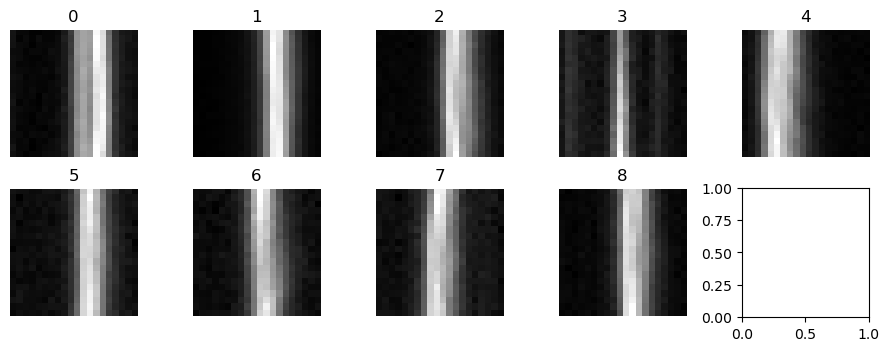

In [311]:
rff.inspect_df_with_quadrant(df_few,'1020')

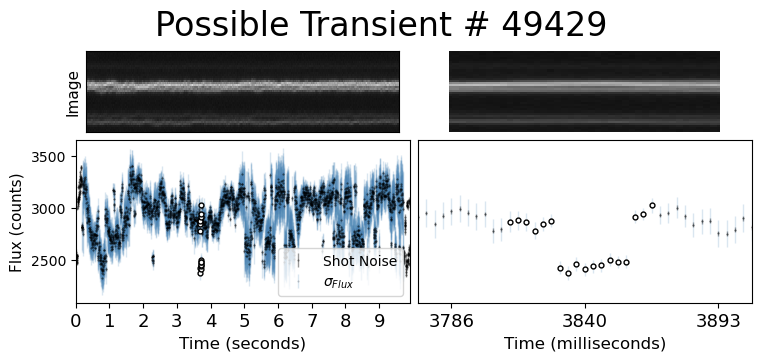

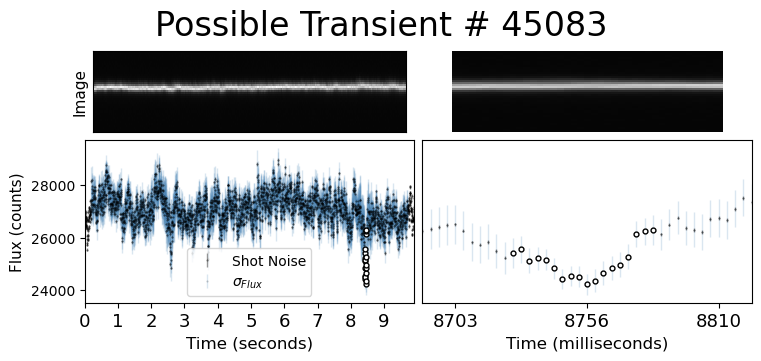

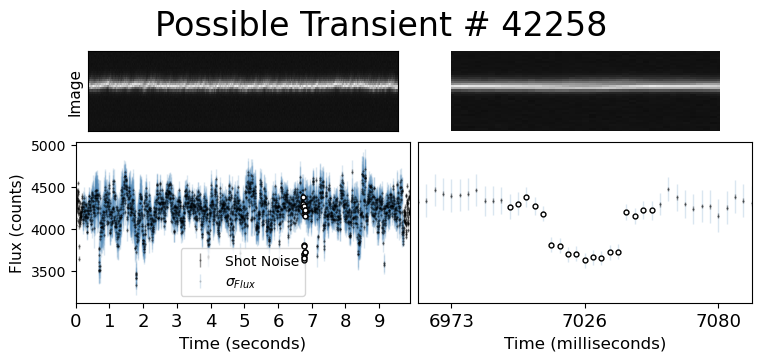

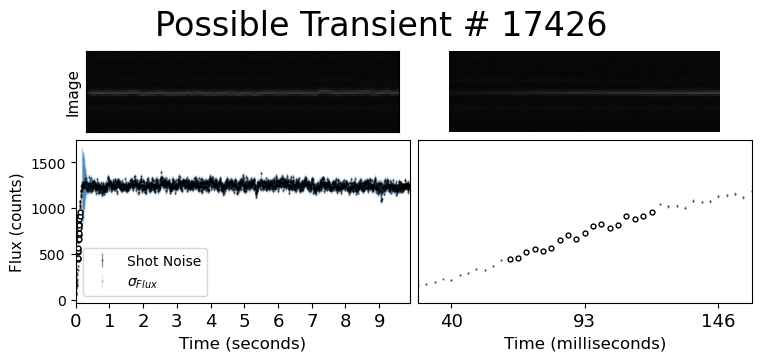

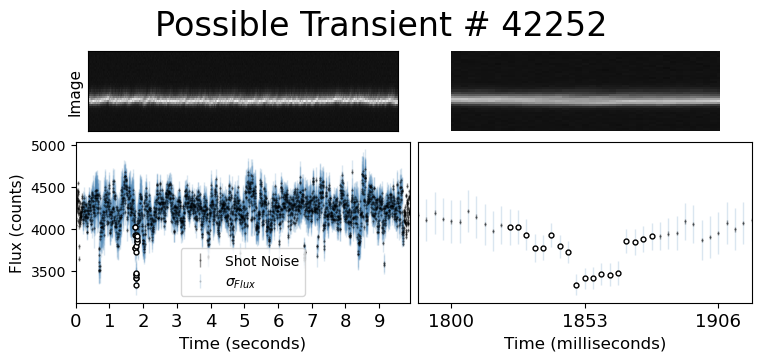

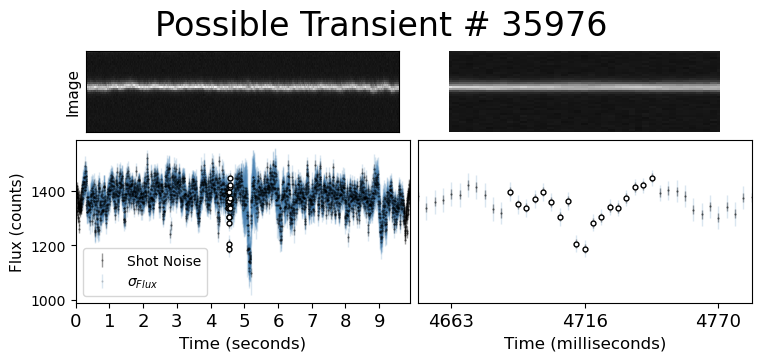

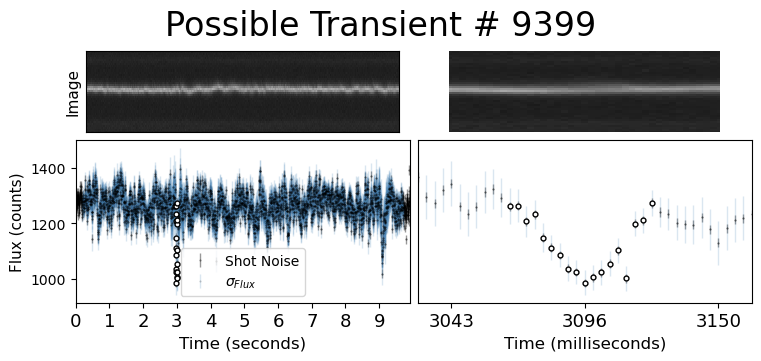

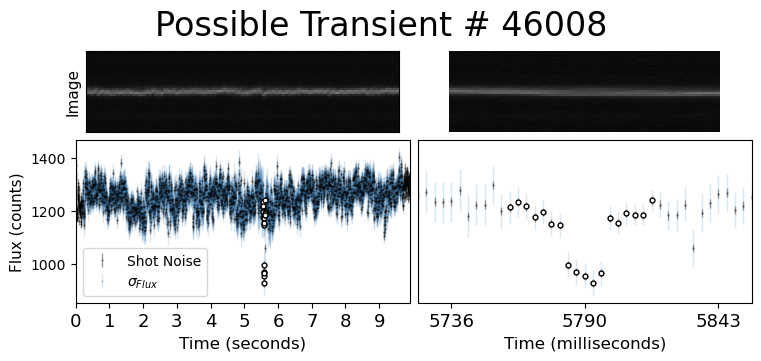

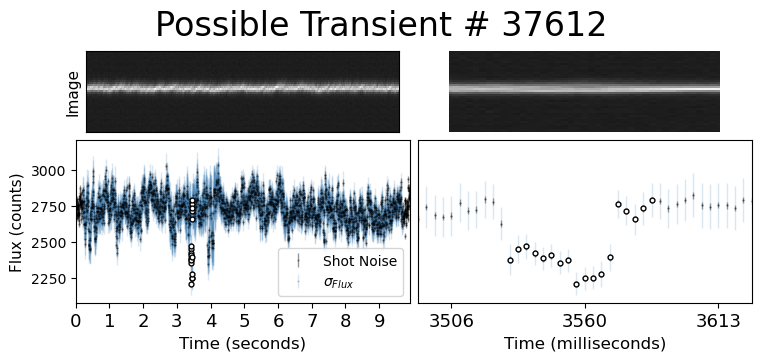

In [314]:
for index in df_few.index:
    rff.plot_time_series_again_aperture(df_candidates_pos_best, index)#, tracking=True, half_aperture=1)

In [ ]:
'''
developing the new signal method using area here
height integrated over 20 pixel width / 20 pixels
'''

In [ ]:
#okay but first let's drop everything with snr<1
#because it will take way too long to run this

In [3]:
df = pd.read_csv("/home/3155/inference_star_info_r12_bands")

In [15]:
df[np.abs(df['snr_center'])<1].index

Int64Index([    4,     5,     7,    13,    14,    15,    16,    19,    23,
               27,
            ...
            51059, 51062, 51066, 51067, 51068, 51069, 51072, 51084, 51088,
            51089],
           dtype='int64', length=15404)

In [16]:
df_snrg1 = df.drop(df[np.abs(df['snr_center'])<1].index)

In [18]:
df_snrg1.to_csv("/home/3155/inference_star_info_r12_bands_snrg1")

In [19]:
df = pd.read_csv("/home/3155/inference_star_info_r12_bands_snrg1")

In [20]:
df

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0,0,0,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,...,22.621652,2.969776,r,2.559791e+18,8.832544,0.59946823,8.453619,9.053087,NOT_AVAILABLE,False
1,1,1,1,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,...,22.621652,2.969776,r,2.559791e+18,8.832544,0.59946823,8.453619,9.053087,NOT_AVAILABLE,False
2,2,2,2,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,...,22.621652,2.969776,r,2.559791e+18,8.832544,0.59946823,8.453619,9.053087,NOT_AVAILABLE,False
3,3,3,3,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,...,303.875960,23.509883,g,1.830576e+18,4.891197,1.1717238,4.235775,5.407499,NOT_AVAILABLE,False
4,6,6,6,45,21,21,236,236,ztf_20221020163819_000640_zg_c01_x_0021.,neg,...,303.875960,23.509883,g,1.830576e+18,4.891197,1.1717238,4.235775,5.407499,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35684,51086,51086,51086,610694,59,59,149,149,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,20.324568,6.970387,r,2.566235e+18,8.553827,1.2051754,7.870535,9.07571,NOT_AVAILABLE,False
35685,51087,51087,51087,610702,67,67,166,166,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35686,51090,51090,51090,610739,104,104,231,231,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35687,51091,51091,51091,610746,111,111,243,243,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#height integrated over 20 pixel width / 20 pixels